# Del dato crudo a la decision por Renzo Rico

Escogí datos del INE y del SEPE (descritos en el README de este repositorio) en España 2025.

## Imports y Limpieza de datos

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

In [2]:
paro_2025 = pd.read_csv('data/raw/Paro_por_municipios_2025_csv.csv',
                        encoding='latin-1',
                        delimiter=';',
                        skiprows=1,
                        dtype={'Codigo Municipio':str})

In [3]:
paro_2025.iloc[0].keys()

Index(['Código mes ', 'mes', 'Código de CA', 'Comunidad Autónoma',
       'Codigo Provincia', 'Provincia', 'Codigo Municipio', ' Municipio',
       'total Paro Registrado', 'Paro hombre edad < 25',
       'Paro hombre edad 25 -45 ', 'Paro hombre edad >=45',
       'Paro mujer edad < 25', 'Paro mujer edad 25 -45 ',
       'Paro mujer edad >=45', 'Paro Agricultura', 'Paro Industria',
       'Paro Construcción', 'Paro Servicios', 'Paro Sin empleo Anterior'],
      dtype='str')

In [4]:
paro_2025.columns = paro_2025.columns.str.strip()

In [5]:
paro_2025.isnull().sum()

Código mes                  0
mes                         0
Código de CA                0
Comunidad Autónoma          0
Codigo Provincia            0
Provincia                   0
Codigo Municipio            0
Municipio                   0
total Paro Registrado       0
Paro hombre edad < 25       0
Paro hombre edad 25 -45     0
Paro hombre edad >=45       0
Paro mujer edad < 25        0
Paro mujer edad 25 -45      0
Paro mujer edad >=45        0
Paro Agricultura            0
Paro Industria              0
Paro Construcción           0
Paro Servicios              0
Paro Sin empleo Anterior    0
dtype: int64

In [6]:
paro_2025.head()

,Código mes,mes,Código de CA,Comunidad Autónoma,Codigo Provincia,Provincia,Codigo Municipio,Municipio,total Paro Registrado,Paro hombre edad < 25,Paro hombre edad 25 -45,Paro hombre edad >=45,Paro mujer edad < 25,Paro mujer edad 25 -45,Paro mujer edad >=45,Paro Agricultura,Paro Industria,Paro Construcción,Paro Servicios,Paro Sin empleo Anterior
0,202501,Enero de 2025,1,Andalucía,4,Almería,04001,Abla,74,5,7,28,<5,14,19,10,<5,6,49,6
1,202501,Enero de 2025,1,Andalucía,4,Almería,04002,Abrucena,55,<5,6,18,<5,14,12,5,<5,6,31,9
2,202501,Enero de 2025,1,Andalucía,4,Almería,04003,Adra,1516,72,208,322,60,357,497,244,52,136,931,153
3,202501,Enero de 2025,1,Andalucía,4,Almería,04004,Albánchez,19,<5,0,8,<5,<5,5,0,<5,<5,12,<5
4,202501,Enero de 2025,1,Andalucía,4,Almería,04005,Alboloduy,25,<5,<5,8,<5,6,5,<5,<5,5,12,<5


In [7]:
ine_2025 = pd.read_csv('data/raw/ine_29005_poblacion_municipios_2025.csv',
                       delimiter=';',
                       thousands='.')


ine_2025

,Municipios,Sexo,Periodo,Total
0,44001 Ababuj,Total,2025,73.0
1,40001 Abades,Total,2025,849.0
2,10001 Abadía,Total,2025,337.0
3,27001 Abadín,Total,2025,2239.0
4,48001 Abadiño,Total,2025,7768.0
...,...,...,...,...
8133,20080 Zumarraga,Total,2025,9678.0
8134,09485 Zuñeda,Total,2025,58.0
8135,48916 Usansolo,Total,2025,4565.0
8136,31265 Zúñiga,Total,2025,78.0


In [8]:
ine_2025.Periodo.unique(), ine_2025.Sexo.unique()

(array([2025]),
 <StringArray>
 ['Total']
 Length: 1, dtype: str)

In [9]:
ine_2025[['Codigo Municipio', 'Municipio']] = ine_2025['Municipios'].str.split(' ', n=1, expand=True)

In [10]:
ine_2025.drop(columns=['Municipios', 'Sexo', 'Periodo'], inplace=True)

In [11]:
ine_2025 = ine_2025[['Municipio', 'Codigo Municipio', 'Total']]
ine_2025

,Municipio,Codigo Municipio,Total
0,Ababuj,44001,73.0
1,Abades,40001,849.0
2,Abadía,10001,337.0
3,Abadín,27001,2239.0
4,Abadiño,48001,7768.0
...,...,...,...
8133,Zumarraga,20080,9678.0
8134,Zuñeda,09485,58.0
8135,Usansolo,48916,4565.0
8136,Zúñiga,31265,78.0


In [12]:
ine_2025.isnull().sum()

Municipio           0
Codigo Municipio    0
Total               6
dtype: int64

In [13]:
ine_2025['Total'].min(), ine_2025['Total'].max(), ine_2025['Total'].skew()

(np.float64(6.0), np.float64(3506730.0), np.float64(48.2636996874899))

In [14]:
ine_2025 = ine_2025.fillna(value=ine_2025['Total'].median())

In [15]:
ine_2025.head()

,Municipio,Codigo Municipio,Total
0,Ababuj,44001,73.0
1,Abades,40001,849.0
2,Abadía,10001,337.0
3,Abadín,27001,2239.0
4,Abadiño,48001,7768.0


## Preguntas a resolver

1. Comunidades y municipios con más paro registrado en relación con su población?
2. Cómo evoluciona el paro durante 2025?
3. Diferencia entre hombres y mujeres?
4. Influye el tamaño del municipio

## Limpieza del paro

In [16]:
# No tenemos valores de 0 a 4 sino <5, por eso las columnas son texto
(paro_2025 == '<5').sum()

Código mes                      0
mes                             0
Código de CA                    0
Comunidad Autónoma              0
Codigo Provincia                0
Provincia                       0
Codigo Municipio                0
Municipio                       0
total Paro Registrado       19109
Paro hombre edad < 25       28065
Paro hombre edad 25 -45     30385
Paro hombre edad >=45       29252
Paro mujer edad < 25        25780
Paro mujer edad 25 -45      27524
Paro mujer edad >=45        26625
Paro Agricultura            30472
Paro Industria              29566
Paro Construcción           28316
Paro Servicios              22154
Paro Sin empleo Anterior    26674
dtype: int64

In [17]:
cols_paro = paro_2025.columns[8:]
# '<5' = entre 1 y 4, uso 2 como valor aproximado para simplificar
paro_2025[cols_paro] = paro_2025[cols_paro].replace('<5', 2).astype(int)
paro_2025.dtypes.tail(12)

total Paro Registrado       int64
Paro hombre edad < 25       int64
Paro hombre edad 25 -45     int64
Paro hombre edad >=45       int64
Paro mujer edad < 25        int64
Paro mujer edad 25 -45      int64
Paro mujer edad >=45        int64
Paro Agricultura            int64
Paro Industria              int64
Paro Construcción           int64
Paro Servicios              int64
Paro Sin empleo Anterior    int64
dtype: object

In [18]:
paro_2025.duplicated(['Código mes', 'Codigo Municipio']).sum(), paro_2025['Código mes'].nunique()

(np.int64(0), 12)

In [19]:
# los sectores deberian sumar mas o menos el total (los 2 inventados desvian un poco)
sectores = ['Paro Agricultura', 'Paro Industria', 'Paro Construcción', 'Paro Servicios', 'Paro Sin empleo Anterior']
dif = paro_2025[sectores].sum(axis=1) - paro_2025['total Paro Registrado']
dif.describe()

count    97620.000000
mean         0.116646
std          1.370350
min         -8.000000
25%          0.000000
50%          0.000000
75%          1.000000
max          6.000000
dtype: float64

## Unir paro + población (DataFrames)

In [20]:
datos = paro_2025.merge(ine_2025[['Codigo Municipio', 'Total']], on='Codigo Municipio', how='left')
datos['Total'].isnull().sum(), len(datos), len(paro_2025)

(np.int64(0), 97620, 97620)

In [21]:
# municipios del INE que no estan en el paro (el fillna con la mediana de antes les afecta pero no entran en el cruce)
sin_paro = ine_2025[~ine_2025['Codigo Municipio'].isin(paro_2025['Codigo Municipio'])]
sin_paro

,Municipio,Codigo Municipio,Total
2117,Cerdedo-Cotobade,36902,5671.0
3085,Gatova,12066,526.0
4968,Palmerola,17122,526.0


In [22]:
datos = datos.rename(columns={
    'Código mes': 'cod_mes', 'Comunidad Autónoma': 'ccaa', 'Provincia': 'provincia', 'Municipio': 'municipio',
    'Codigo Municipio': 'cod_municipio', 'Total': 'poblacion', 'total Paro Registrado': 'paro_total',
    'Paro hombre edad < 25': 'h_menor25', 'Paro hombre edad 25 -45': 'h_25_45', 'Paro hombre edad >=45': 'h_mayor45',
    'Paro mujer edad < 25': 'm_menor25', 'Paro mujer edad 25 -45': 'm_25_45', 'Paro mujer edad >=45': 'm_mayor45',
    'Paro Agricultura': 'agricultura', 'Paro Industria': 'industria', 'Paro Construcción': 'construccion',
    'Paro Servicios': 'servicios', 'Paro Sin empleo Anterior': 'sin_empleo_ant'})

datos = datos[['cod_mes', 'cod_municipio', 'municipio', 'provincia', 'ccaa', 'poblacion', 'paro_total',
               'h_menor25', 'h_25_45', 'h_mayor45', 'm_menor25', 'm_25_45', 'm_mayor45',
               'agricultura', 'industria', 'construccion', 'servicios', 'sin_empleo_ant']]

datos['paro_por_100_hab'] = datos.paro_total / datos.poblacion * 100

datos.to_csv('data/processed/paro_poblacion_2025.csv', index=False)

# datos.shape

In [37]:
datos.shape

(97620, 19)

## SQL
Misma tabla en duckdb, las consultas están en el folder sql/ y como comentarios aqui.

In [23]:
import duckdb
con = duckdb.connect()
con.register('datos', datos)

def consulta(archivo):
    return con.sql(open(f'sql/{archivo}').read()).df()

In [38]:
# q1_ccaa.sql

# -- tasa de paro por comunidad en diciembre
# select ccaa,
#        sum(paro_total) as paro,
#        sum(poblacion) as poblacion,
#        round(sum(paro_total) * 100.0 / sum(poblacion), 2) as paro_por_100_hab
# from datos
# where cod_mes = 202512
# group by ccaa
# order by paro_por_100_hab desc


In [24]:
q1 = consulta('q1_ccaa.sql')
q1

,ccaa,paro,poblacion,paro_por_100_hab
0,Ceuta,8760.0,83595.0,10.48
1,Melilla,7671.0,86780.0,8.84
2,Andalucía,583052.0,8666412.0,6.73
3,Canarias,146293.0,2249976.0,6.50
4,Extremadura,64364.0,1051638.0,6.12
5,Castilla - La Mancha,116768.0,2119234.0,5.51
6,Comunitat Valenciana,289924.0,5415843.0,5.35
7,"Asturias, Principado de",51195.0,1013529.0,5.05
8,País Vasco,107432.0,2242342.0,4.79
9,Cantabria,27897.0,593964.0,4.70


In [ ]:
# q2_municipios.sql

# -- municipios grandes (>= 20000 hab) con mas paro por habitante

# select municipio, provincia, poblacion, paro_total,
#        round(paro_total * 100.0 / poblacion, 2) as paro_por_100_hab
# from datos
# where cod_mes = 202512 and poblacion >= 20000
# order by paro_por_100_hab desc
# limit 10


In [25]:
q2 = consulta('q2_municipios.sql')
q2

,municipio,provincia,poblacion,paro_total,paro_por_100_hab
0,"Línea de la Concepción, La",Cádiz,64499.0,8093,12.55
1,Ceuta,Ceuta,83595.0,8760,10.48
2,Arcos de la Frontera,Cádiz,31267.0,3188,10.20
3,Jerez de la Frontera,Cádiz,213634.0,20813,9.74
4,Algeciras,Cádiz,126589.0,12256,9.68
5,Barbate,Cádiz,22635.0,2174,9.60
6,San Juan de Aznalfarache,Sevilla,23408.0,2178,9.30
7,Camas,Sevilla,29089.0,2702,9.29
8,Utrera,Sevilla,52403.0,4808,9.18
9,Sanlúcar de Barrameda,Cádiz,70012.0,6258,8.94


In [ ]:
# q3_mensual.sql

# -- evolucion mensual del paro total, hombres vs mujeres
# select cod_mes,
#        sum(paro_total) as paro,
#        sum(h_menor25 + h_25_45 + h_mayor45) as hombres,
#        sum(m_menor25 + m_25_45 + m_mayor45) as mujeres
# from datos
# group by cod_mes
# order by cod_mes


In [26]:
q3 = consulta('q3_mensual.sql')
q3

,cod_mes,paro,hombres,mujeres
0,202501,2598988.0,1036161.0,1563532.0
1,202502,2593037.0,1030644.0,1562999.0
2,202503,2579640.0,1026487.0,1553721.0
3,202504,2512226.0,997395.0,1515512.0
4,202505,2454420.0,968727.0,1486401.0
5,202506,2405520.0,945317.0,1460862.0
6,202507,2404124.0,944924.0,1460090.0
7,202508,2426043.0,955071.0,1471774.0
8,202509,2421207.0,953014.0,1468931.0
9,202510,2443335.0,963556.0,1480534.0


## Análisis

In [40]:
# lo mismo de q1 en pandas, para comprobar que sale igual
dic = datos[datos.cod_mes == 202512]
ccaa_pd = dic.groupby('ccaa')[['paro_total', 'poblacion']].sum()
ccaa_pd['tasa'] = ccaa_pd.paro_total / ccaa_pd.poblacion * 100
print(np.allclose(ccaa_pd.tasa.sort_index().round(2).values, q1.set_index('ccaa').paro_por_100_hab.sort_index().values))
ccaa_pd.sort_values('tasa', ascending=False)

True


,paro_total,poblacion,tasa
ccaa,,,
Ceuta,8760,83595.0,10.479096
Melilla,7671,86780.0,8.839594
Andalucía,583052,8666412.0,6.727721
Canarias,146293,2249976.0,6.501980
Extremadura,64364,1051638.0,6.120357
Castilla - La Mancha,116768,2119234.0,5.509915
Comunitat Valenciana,289924,5415843.0,5.353257
"Asturias, Principado de",51195,1013529.0,5.051163
País Vasco,107432,2242342.0,4.791062


Un screenshot de la tabla q1 en duckdb para comparar mejor

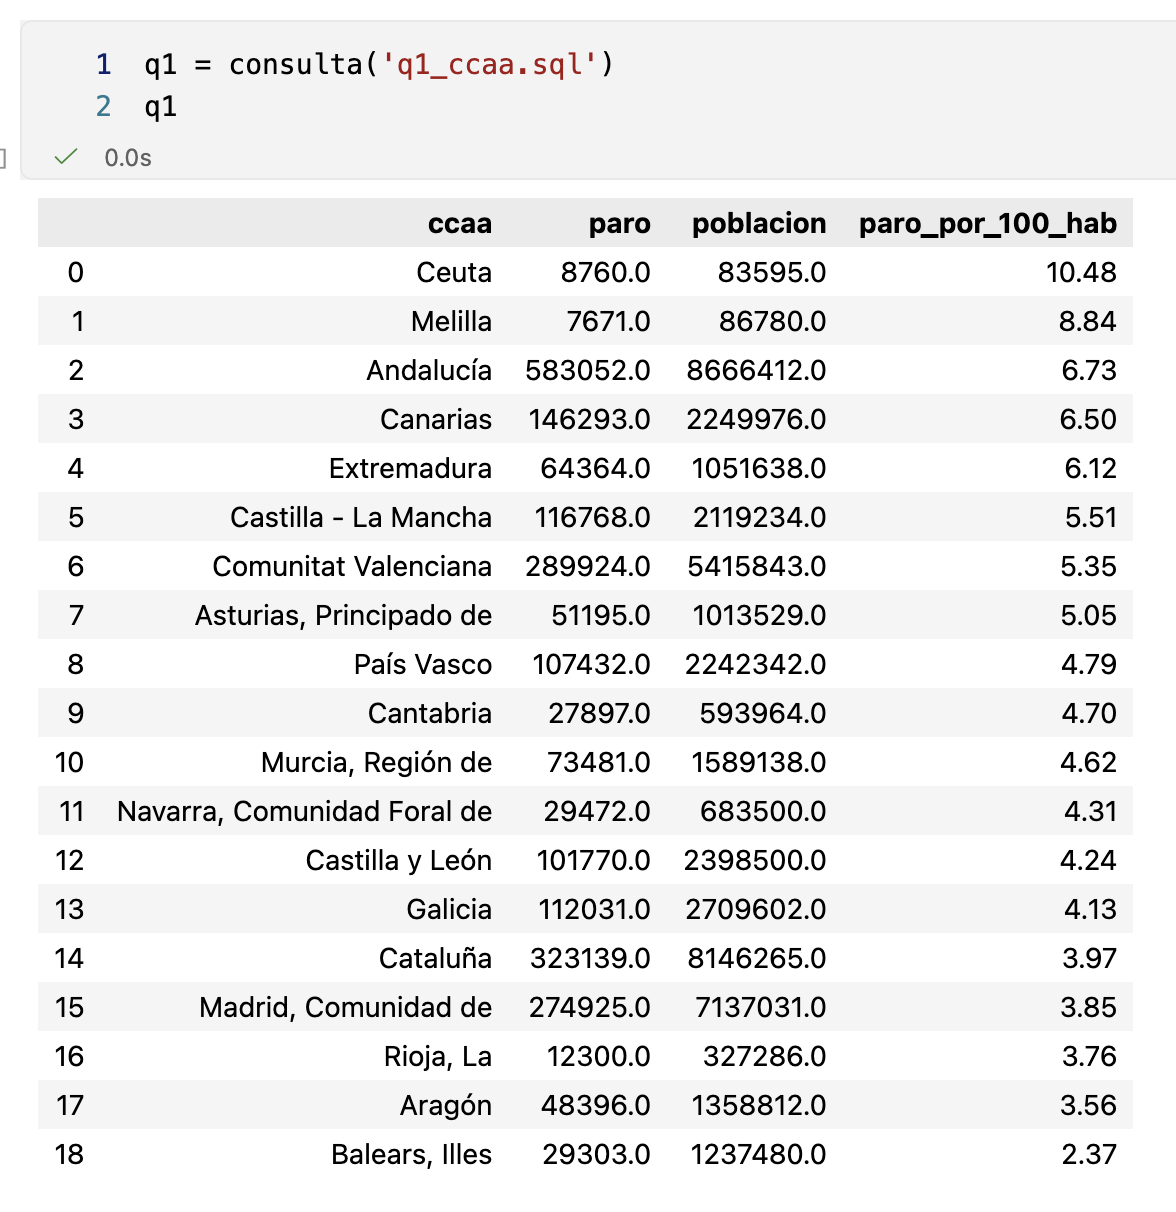

In [28]:
# maximo y minimo del año
q3['variacion'] = q3.paro.pct_change() * 100
q3.paro.max(), q3.paro.min(), (q3.paro.iloc[-1] / q3.paro.iloc[0] - 1) * 100

(np.float64(2598988.0), np.float64(2404124.0), np.float64(-7.341896153425875))

In [ ]:
# brecha de género en diciembre
h = dic[['h_menor25', 'h_25_45', 'h_mayor45']].sum()
m = dic[['m_menor25', 'm_25_45', 'm_mayor45']].sum()

pd.DataFrame({'hombres': h.values, 'mujeres': m.values}, index=['<25', '25-45', '>=45']).assign(
    mujeres_pct=lambda x: x.mujeres / (x.hombres + x.mujeres) * 100)

,hombres,mujeres,mujeres_pct
<25,94284,83070,46.838526
25-45,324043,504487,60.889407
>=45,546541,856585,61.048331


In [30]:
sec = dic[['agricultura', 'industria', 'construccion', 'servicios', 'sin_empleo_ant']].sum()
(sec / sec.sum() * 100).round(1)

agricultura        3.1
industria          7.8
construccion       7.4
servicios         72.5
sin_empleo_ant     9.2
dtype: float64

In [31]:
# tamaño vs tasa. spearman porque la poblacion esta muy sesgada (skew 48)
dic[['poblacion', 'paro_por_100_hab']].corr(method='spearman')

,poblacion,paro_por_100_hab
poblacion,1.000000,0.342077
paro_por_100_hab,0.342077,1.000000


In [32]:
dic['tramo'] = pd.cut(dic.poblacion, [0, 1000, 5000, 20000, 100000, 5e6],
                      labels=['<1k', '1k-5k', '5k-20k', '20k-100k', '>100k'])
dic.groupby('tramo', observed=True).agg(municipios=('municipio', 'count'),
                                       mediana=('paro_por_100_hab', 'median'),
                                       desv=('paro_por_100_hab', 'std'))

,municipios,mediana,desv
tramo,,,
<1k,4985,3.125000,2.496338
1k-5k,1826,4.129132,1.713520
5k-20k,892,4.328698,1.633262
20k-100k,365,4.891681,1.695710
>100k,67,4.879590,1.571393


## Visualización

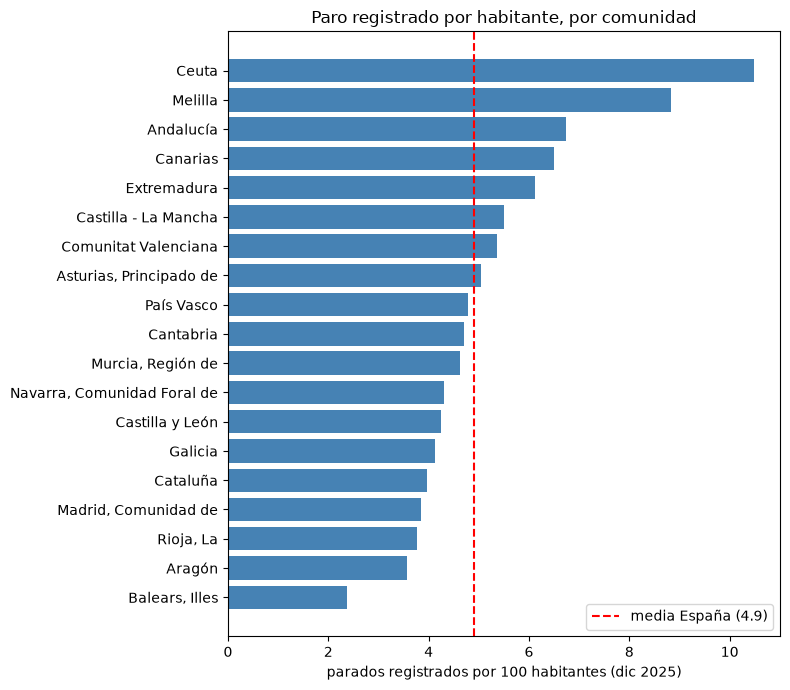

In [33]:
orden = ccaa_pd.sort_values('tasa')
media = dic.paro_total.sum() / dic.poblacion.sum() * 100

fig, ax = plt.subplots(figsize=(8, 7))
ax.barh(orden.index, orden.tasa, color='steelblue')
ax.axvline(media, color='red', linestyle='--', label=f'media España ({media:.1f})')
ax.set_xlabel('parados registrados por 100 habitantes (dic 2025)')
ax.set_title('Paro registrado por habitante, por comunidad')
ax.legend()
plt.tight_layout()
plt.savefig('img/tasa_ccaa.png', dpi=150)
plt.show()

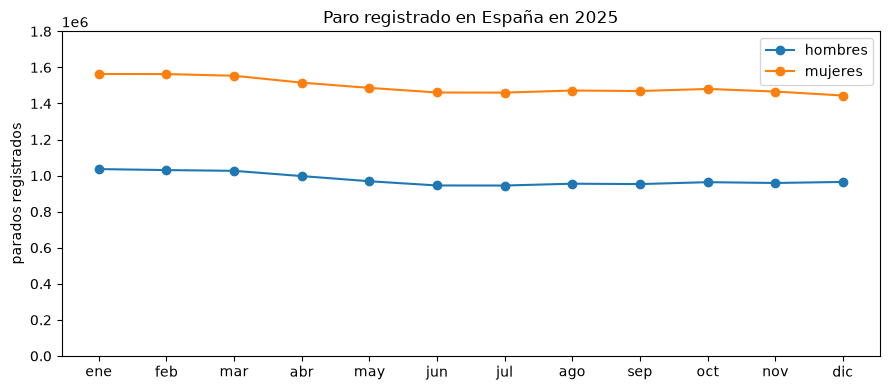

In [34]:
fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(q3.cod_mes.astype(str), q3.hombres, marker='o', label='hombres')
ax.plot(q3.cod_mes.astype(str), q3.mujeres, marker='o', label='mujeres')
ax.set_xticks(range(12))
ax.set_xticklabels(['ene', 'feb', 'mar', 'abr', 'may', 'jun', 'jul', 'ago', 'sep', 'oct', 'nov', 'dic'])
ax.set_ylabel('parados registrados')
ax.set_ylim(0, 1.8e6)
ax.set_title('Paro registrado en España en 2025')
ax.legend()
plt.tight_layout()
plt.savefig('img/evolucion_mensual.png', dpi=150)
plt.show()

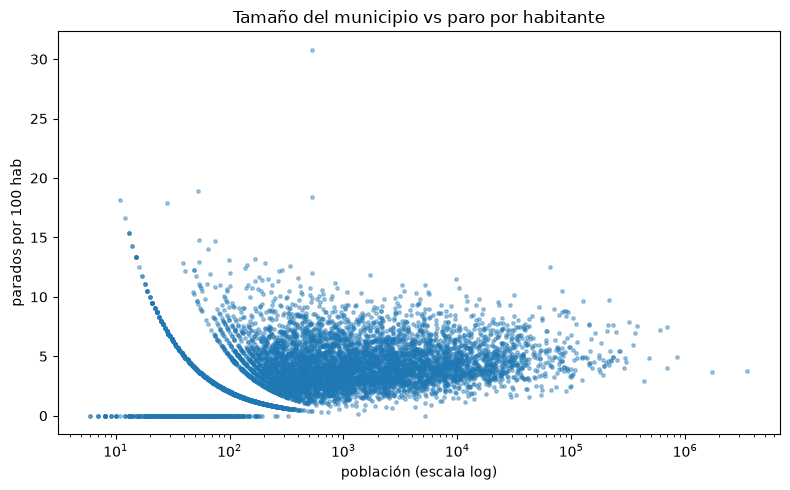

In [35]:
fig, ax = plt.subplots(figsize=(8, 5))
ax.scatter(dic.poblacion, dic.paro_por_100_hab, s=6, alpha=0.4)
ax.set_xscale('log')
ax.set_xlabel('población (escala log)')
ax.set_ylabel('parados por 100 hab')
ax.set_title('Tamaño del municipio vs paro por habitante')
plt.tight_layout()
plt.savefig('img/poblacion_vs_tasa.png', dpi=150)
plt.show()

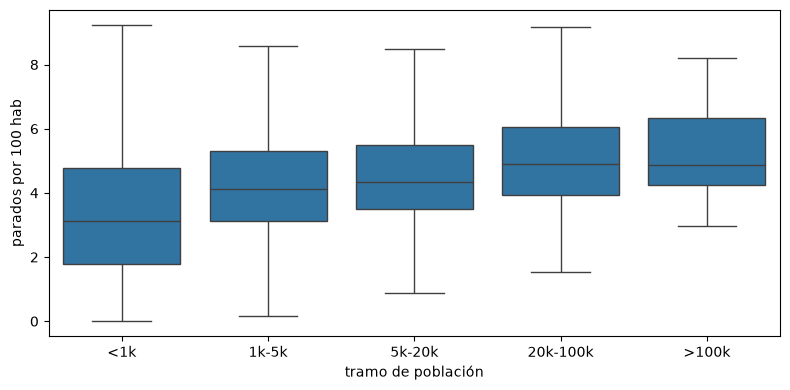

In [36]:
fig, ax = plt.subplots(figsize=(8, 4))
sns.boxplot(data=dic, x='tramo', y='paro_por_100_hab', ax=ax, showfliers=False)
ax.set_xlabel('tramo de población')
ax.set_ylabel('parados por 100 hab')
plt.tight_layout()
plt.savefig('img/tasa_por_tramo.png', dpi=150)
plt.show()

## Conclusiones

A diciembre de 2025 hay unos 2,41 millones de parados registrados, algo menos de 5 por cada 100 habitantes. Desde enero han bajado un 7%, casi todo entre abril y junio, y desde verano se queda más o menos igual.

Por comunidades, Ceuta y Melilla son las que peor salen (10,5 y 8,8 por 100 hab), después Andalucía y Canarias. Las mejores son Baleares (2,4), Aragón y La Rioja. Entre los municipios grandes lo que más llama la atención es Cádiz: La Línea, Arcos, Jerez, Algeciras y Barbate están todos por encima de 9. También salen varios de Sevilla (Camas, San Juan de Aznalfarache, Utrera).

Las mujeres son el 60% del paro y la diferencia se ve a partir de los 25. Entre los menores de 25 está casi 50/50. Por sectores, 7 de cada 10 parados vienen de servicios.

Sobre el tamaño: los municipios de menos de 1.000 habitantes tienen la tasa mediana más baja (3,1), pero ahí hay de todo, de 0 a 30, así que no me fío mucho. La correlación entre población y tasa es 0,34, algo hay pero no es muy fuerte.

## Recomendación

Yo empezaría por Cádiz y el área de Sevilla, más Ceuta y Melilla, que son donde más pesa el paro. Y haría algo específico para mujeres de más de 25 años, que son la mayoría. Los jóvenes no destacan aquí, aunque para decirlo bien habría que calcular la tasa sobre su población y no solo contar personas.

## Limitaciones

- Paro registrado es solo la gente apuntada al SEPE, no es el paro real ni el de la EPA.
- Dividí entre la población total y no entre la población en edad de trabajar. Sirve para comparar zonas pero no es la tasa de paro oficial.
- Los `<5` los cambié por 2, es una aproximación mía. En municipios pequeños se nota (un 26% sale con 2 o menos parados) y por eso los sectores no suman exactamente el total.
- La población es de un solo año (2025) y la usé para los 12 meses.
- Seis municipios del INE venían sin población y puse la mediana. Son códigos antiguos de municipios fusionados y no cruzan con el paro, así que no afecta.
- Con un solo año no puedo hablar de tendencia, solo de lo que pasó en 2025.

## Ética

Los datos son agregados y públicos, no hay datos personales. Aun así, un ranking de municipios con más paro puede estigmatizar a esas zonas, y si alguien lo usara para repartir ayudas con una tasa como la mía (sobre población total) podría perjudicar a pueblos pequeños o con mucha gente mayor. Para decidir algo de verdad habría que usar la tasa oficial y más años.
